# Ni: 2D → 1D integration and Rietveld refinement with easyXRD

This notebook processes the 2D synchrotron diffraction image **`Ni.tiff`** into a 1D powder profile with pyFAI,
then runs a Rietveld refinement with GSAS-II. Both steps use the **`easyxrd`** library, following the workflow
in the [easyXRD_examples](https://github.com/MehmetTopsakal/easyXRD_examples) notebooks
(`01_basic`, `02_intermediate`, `03_advanced-part-1/2`).

**Input files (all in this folder)**

| File | Purpose |
|---|---|
| `Ni.tiff` | 2D detector image (Dexela 2923) of the Ni powder |
| `_calibration.poni` | pyFAI detector geometry (λ = 0.1799 Å, distance ≈ 0.600 m) |
| `_mask.edf` | Bad-pixel / gap mask for pyFAI |
| `Ni.cif` | Ni crystal structure (Fm-3m) used for phase matching |
| `_instrument_parameters.gpx` | GSAS-II project holding calibrated instrument profile parameters (U, V, W, X, Y, Z, SH/L) |

**Workflow**

1. Inspect the raw image and mask
2. Azimuthal integration (pyFAI via `easyxrd`) → `i2d` (cake) and `i1d` (1D profile)
3. Choose a radial (q) range and export the 1D profile
4. Load the Ni phase from the CIF and check the peak match
5. Set up the GSAS-II refiner with instrument parameters from `_instrument_parameters.gpx`
6. Le Bail stage: background → lattice → size/strain broadening
7. Rietveld stage: structure-factor intensities → preferred orientation → Uiso → final refinement
8. Results and export (`.gpx`, `.nc`, figures)

## 1. Imports and configuration

In [1]:
import os
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import fabio
import pyFAI

import easyxrd
from easyxrd.core import exrd

%matplotlib inline
plt.rcParams["figure.constrained_layout.use"] = True
pyFAI.use_opencl = False

# Work in the folder that holds the data files
data_dir = Path("/home/mt/temp/7_Su")
os.chdir(data_dir)
print(f"Working directory: {Path.cwd()}")
print(f"pyFAI version: {pyFAI.version}")
easyxrd.show_config()

Working directory: /home/mt/temp/7_Su
pyFAI version: 2026.9.0
easyXRD environment and configurations
Platform            : Linux-7.1.5-76070105-generic-x86_64-with-glibc2.39
python              : 3.14.8
executable          : /home/mt/mpixi/.pixi/envs/default/bin/python
easyxrd             : 2026.10.20.post2
pyFAI               : 2026.9.0
fabio               : 2026.6.0
numpy               : 2.5.4
scipy               : 1.18.1
pandas              : 3.0.6
pymatgen            : 2026.9.24
GSAS-II             : 2.0.0
GSASII_module       : /home/mt/mpixi/.pixi/envs/default/lib/python3.14/site-packages/GSASII/GSASIIscriptable.py
easyxrd_scratch_path: /home/mt/.easyxrd_scratch
gsasii_lib_path     : /home/mt/mpixi/.pixi/envs/default/lib/python3.14/site-packages/GSASII
mp_api_key          : dHgNQ......
----------------------------------------



## 2. Inspect the raw detector image, mask and calibration

Image shape : (3888, 3072), dtype=float32, min=-145.8, max=6903.6
Mask shape  : (3888, 3072), masked pixels = 54514 (0.46 %)

Detector Dexela 2923	 PixelSize= 75µm, 75µm	 BottomRight (3)
Wavelength= 0.179900 Å
SampleDetDist= 5.994972e-01 m	PONI= 1.406570e-01, 9.934597e-02 m	rot1=-0.023867  rot2=0.007321  rot3=0.000000 rad
DirectBeamDist= 599.684 mm	Center: x=1515.422, y=1933.965 pix	Tilt= 1.430° tiltPlanRotation= 17.056° λ= 0.180Å


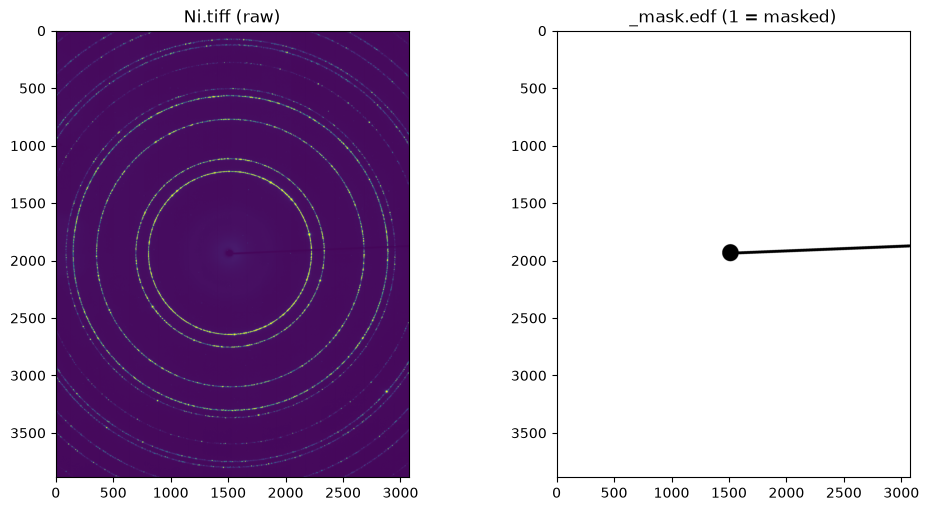

In [2]:
img = fabio.open("Ni.tiff").data
mask = fabio.open("_mask.edf").data
ai = pyFAI.load("_calibration.poni")

print(f"Image shape : {img.shape}, dtype={img.dtype}, min={img.min():.1f}, max={img.max():.1f}")
print(f"Mask shape  : {mask.shape}, masked pixels = {int(mask.sum())} ({100*mask.mean():.2f} %)")
print()
print(ai)

fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].imshow(img, vmin=0, vmax=np.percentile(img, 99.5), cmap="viridis")
axs[0].set_title("Ni.tiff (raw)")
axs[1].imshow(mask, cmap="gray_r")
axs[1].set_title("_mask.edf (1 = masked)")
plt.show()

## 3. Azimuthal integration with pyFAI (through `easyxrd`)

`exrd.load_xrd_data` reads the TIFF, applies the PONI geometry and mask, and integrates the image. It produces:
* `ds.i2d`: the "cake" (azimuthal angle vs. q)
* `ds.i1d`: the azimuthally averaged 1D profile

We first integrate over the default q range to see everything the detector covers.

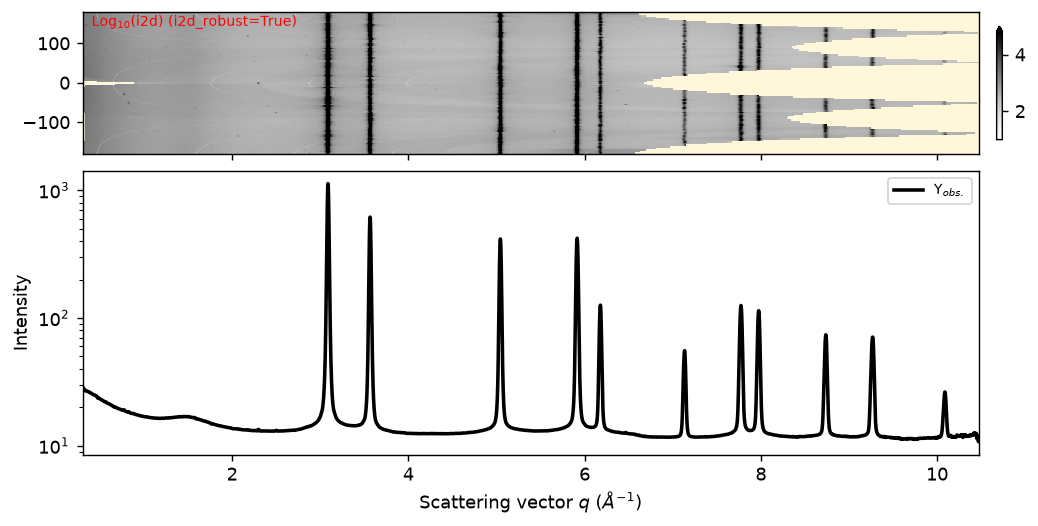

In [3]:
sample_full = exrd()
sample_full.load_xrd_data(
    from_tiff_file="Ni.tiff",          # 2D image
    poni_file="_calibration.poni",     # geometry from pyFAI-calib2
    mask_file="_mask.edf",             # bad-pixel mask
    plot=True,
)

### Choosing the radial range

The detector sits off-centre, so complete Debye–Scherrer rings only reach q ≈ 6.5 Å⁻¹. Beyond that, fewer
azimuthal bins have data (the yellow masked areas in the cake), and above ≈ 10 Å⁻¹ only a few bins remain.
The cell below counts the valid azimuthal bins as a function of q.

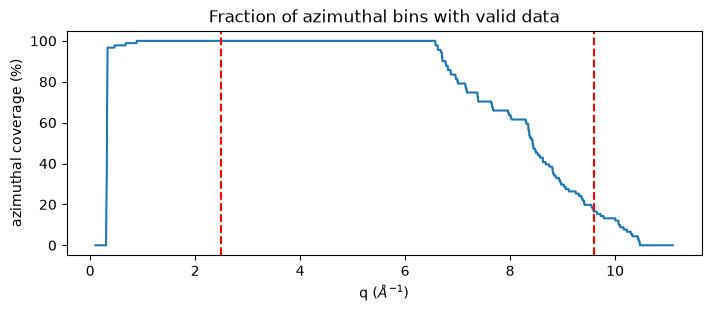

 (1, 1, 1)  q =  3.087 1/A   coverage = 100.0 %
 (2, 0, 0)  q =  3.564 1/A   coverage = 100.0 %
 (2, 2, 0)  q =  5.041 1/A   coverage = 100.0 %
 (3, 1, 1)  q =  5.911 1/A   coverage = 100.0 %
 (2, 2, 2)  q =  6.174 1/A   coverage = 100.0 %
 (4, 0, 0)  q =  7.129 1/A   coverage =  79.1 %
 (3, 3, 1)  q =  7.768 1/A   coverage =  65.9 %
 (4, 2, 0)  q =  7.970 1/A   coverage =  64.8 %
 (4, 2, 2)  q =  8.731 1/A   coverage =  39.6 %
 (5, 1, 1)  q =  9.260 1/A   coverage =  25.3 %
 (4, 4, 0)  q = 10.081 1/A   coverage =   9.9 %


In [4]:
coverage = np.isfinite(sample_full.ds.i2d).sum("azimuthal_i2d")
n_azim = sample_full.ds.sizes["azimuthal_i2d"]

fig, ax = plt.subplots(figsize=(7, 3))
(coverage / n_azim * 100).plot(ax=ax)
ax.set_ylabel("azimuthal coverage (%)")
ax.set_xlabel(r"q ($\AA^{-1}$)")
for q_lim in (2.5, 9.6):
    ax.axvline(q_lim, color="r", ls="--")
ax.set_title("Fraction of azimuthal bins with valid data")
plt.show()

# Expected Ni (Fm-3m) reflections with the CIF lattice constant
a0 = 3.52557618
hkls = [(1,1,1),(2,0,0),(2,2,0),(3,1,1),(2,2,2),(4,0,0),(3,3,1),(4,2,0),(4,2,2),(5,1,1),(4,4,0)]
for h in hkls:
    q = 2*np.pi*np.sqrt(sum(i*i for i in h))/a0
    print(f"{str(h):>10s}  q = {q:6.3f} 1/A   coverage = {100*float(coverage.sel(radial_i2d=q, method='nearest'))/n_azim:5.1f} %")

We use **q = 2.5 – 9.6 Å⁻¹**. This range:
* starts below Ni(111) (q ≈ 3.09 Å⁻¹) and skips the featureless low-q region,
* contains 10 Ni reflections, (111) through (511)/(333),
* stops before (440), where less than ~15 % of the ring is on the detector.

Wavelength from PONI: 0.1799 A


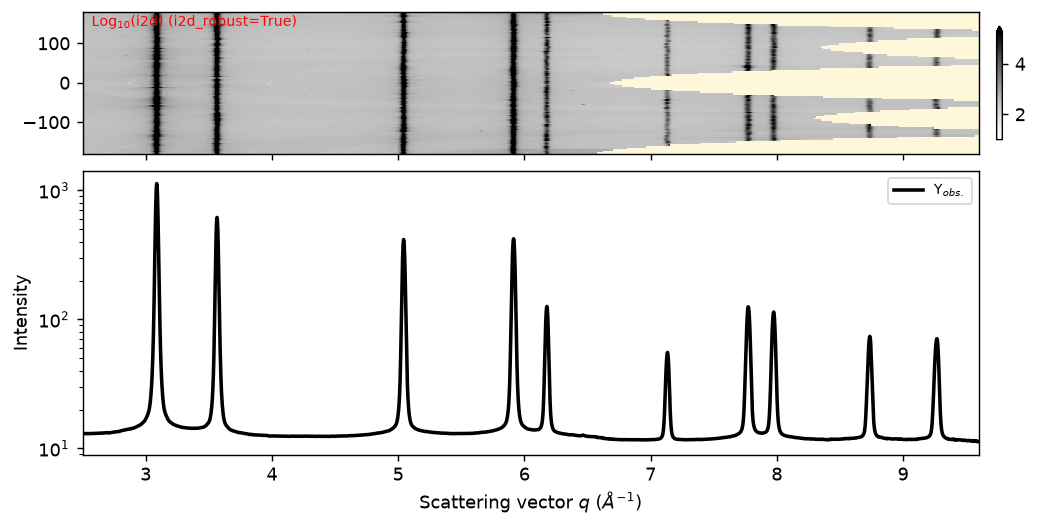

In [5]:
sample = exrd()
sample.load_xrd_data(
    from_tiff_file="Ni.tiff",
    poni_file="_calibration.poni",
    mask_file="_mask.edf",
    radial_range=[2.5, 9.6],
    plot=True,
)
print(f"Wavelength from PONI: {sample.ds.i1d.attrs['wavelength_in_angst']:.4f} A")

### Export the 1D profile

The integrated pattern is saved in q and in 2θ (degrees), so it can be used outside this notebook.

In [6]:
sample.export_i1d_to("Ni_i1d_q.xy", mode="qxy", header=True)
sample.export_i1d_to("Ni_i1d_2theta.xy", mode="xy", header=True)
sample.export_ds_to("Ni_integrated.nc")
print("Saved: Ni_i1d_q.xy, Ni_i1d_2theta.xy, Ni_integrated.nc")

Saved: Ni_i1d_q.xy, Ni_i1d_2theta.xy, Ni_integrated.nc


## 4. Load the Ni phase from `Ni.cif` (phase matching)

The stem lines in the bottom subplot are the reflections calculated from the CIF. They line up with every
observed peak, so the sample is single-phase fcc Ni. The small offset at high q comes from the CIF
lattice constant (a = 3.5256 Å), which the refinement will correct.

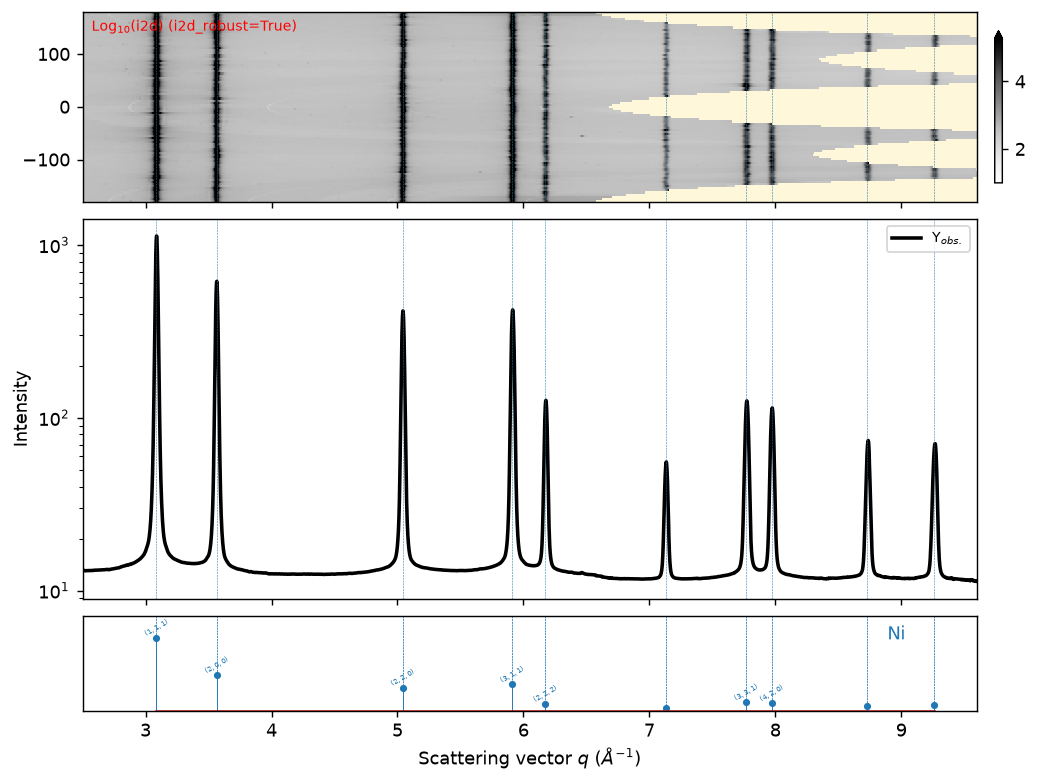

In [7]:
sample.load_phases([{"cif": "Ni.cif", "label": "Ni"}], plot=True)

## 5. GSAS-II refiner with instrument parameters from `_instrument_parameters.gpx`

`_instrument_parameters.gpx` is a GSAS-II project from a LaB6 calibrant refinement at the same wavelength
(0.1799 Å). Its profile parameters (U, V, W, X, Y, Z, SH/L) describe the instrumental broadening. Here is what it contains:

In [8]:
import GSASII.GSASIIscriptable as G2sc

gpx_inst = G2sc.G2Project(gpxfile="_instrument_parameters.gpx")
inst = gpx_inst.histograms()[0].data["Instrument Parameters"][0]
print(f"{'param':>9s} {'value':>12s}")
for k in ["Type", "Lam", "Polariz.", "Azimuth", "Zero", "U", "V", "W", "X", "Y", "Z", "SH/L"]:
    v = inst[k][1]
    print(f"{k:>9s} {v:>12.5f}" if not isinstance(v, str) else f"{k:>9s} {v:>12s}")

    param        value
     Type          PXC
      Lam      0.17990
 Polariz.      0.00000
  Azimuth      0.00000
     Zero      0.00000
        U    -29.42957
        V     13.79134
        W      0.87089
        X      0.07517
        Y     -1.08440
        Z      0.04077
     SH/L      0.00554


`setup_gsas2_refiner(instprm_from_gpx=...)` passes these calibrated parameters to GSAS-II, together with the
wavelength of the integrated data. The **instrument parameters stay fixed** for the rest of the notebook
(they come from the LaB6 standard). Peak broadening beyond the instrument is modelled with sample
parameters (crystallite size and microstrain). The setup also runs a first Le Bail fit.

 ✅--1st refinement with LeBail is completed. Rwp/GoF is 26.813/1.324


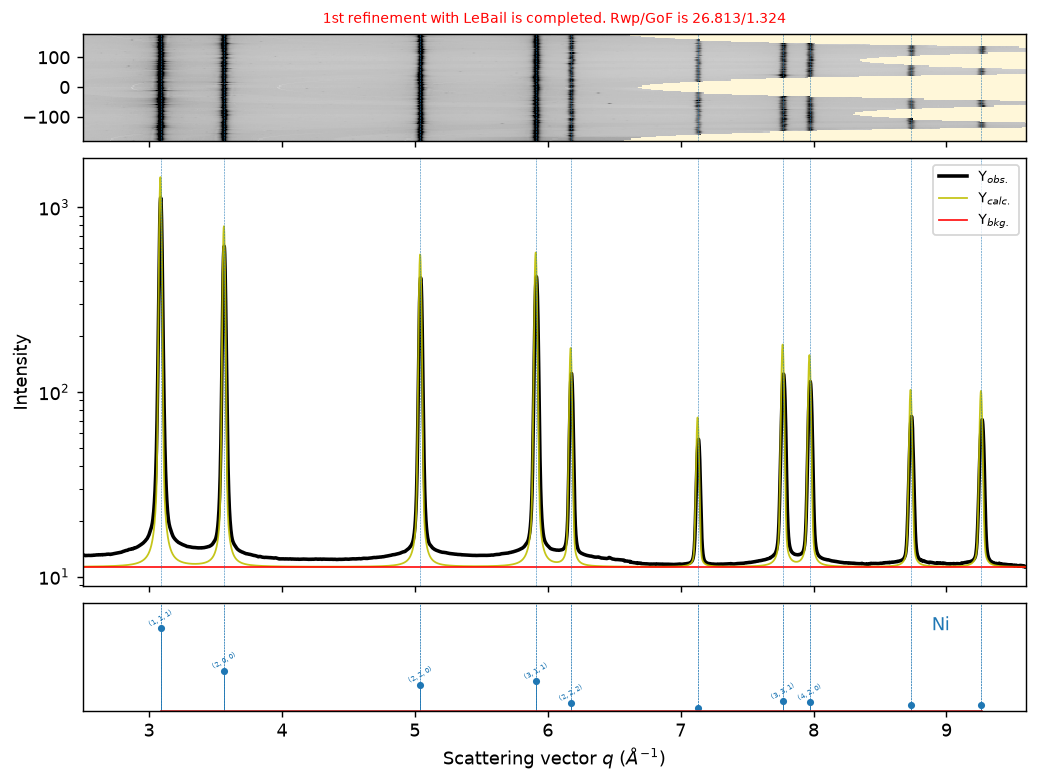

In [9]:
sample.setup_gsas2_refiner(
    instprm_from_gpx="_instrument_parameters.gpx",
    plot=True,
)

## 6. Le Bail stage

In Le Bail mode, peak intensities are extracted freely, so we can optimise the background, peak positions
(lattice) and peak widths without involving the structure.

 ✅--Background with 5 coeffs is refined. Rwp/GoF is now 22.784/1.126 (was 26.813(-15.03%)/1.324(-15.00%✨))


 ✅--Background with 10 coeffs is refined. Rwp/GoF is now 22.322/1.103 (was 22.784(-2.03%)/1.126(-1.99%))


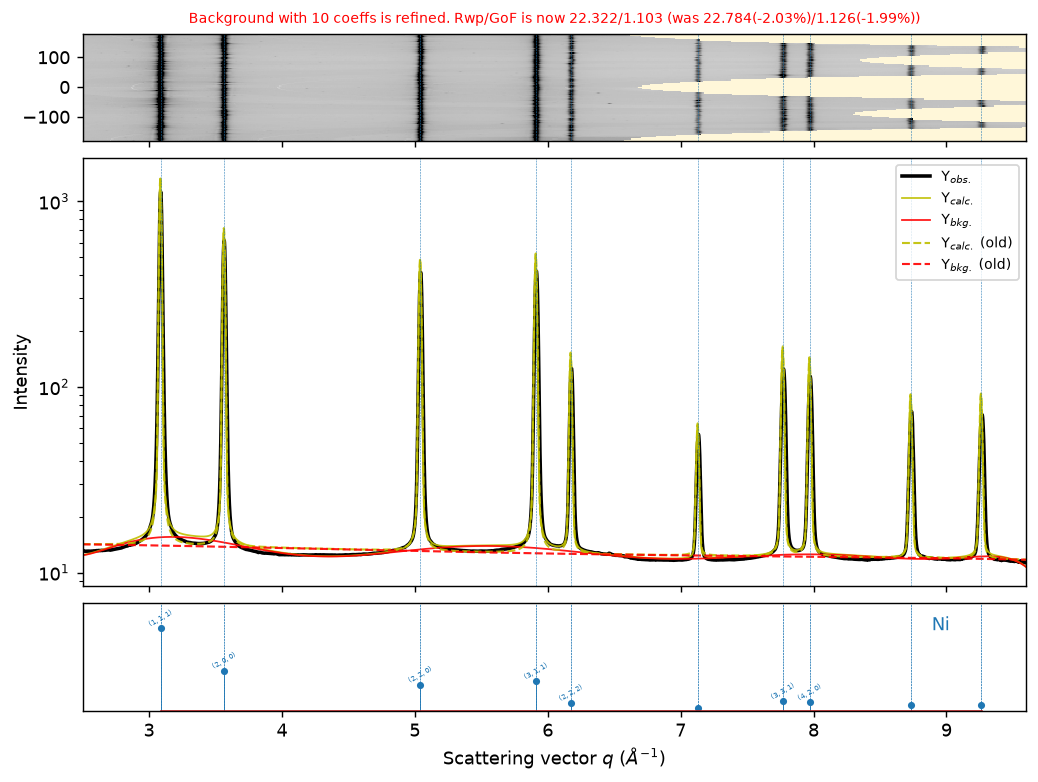

In [10]:
# Background: Chebyshev polynomial, increasing the number of coefficients step by step
sample.refine_background(num_coeffs=5, plot=False)
sample.refine_background(num_coeffs=10, plot=True)

 ✅--Cell parameters are refined. Rwp/GoF is now 13.784/0.681 (was 22.322(-38.25%)/1.103(-38.29%✨))


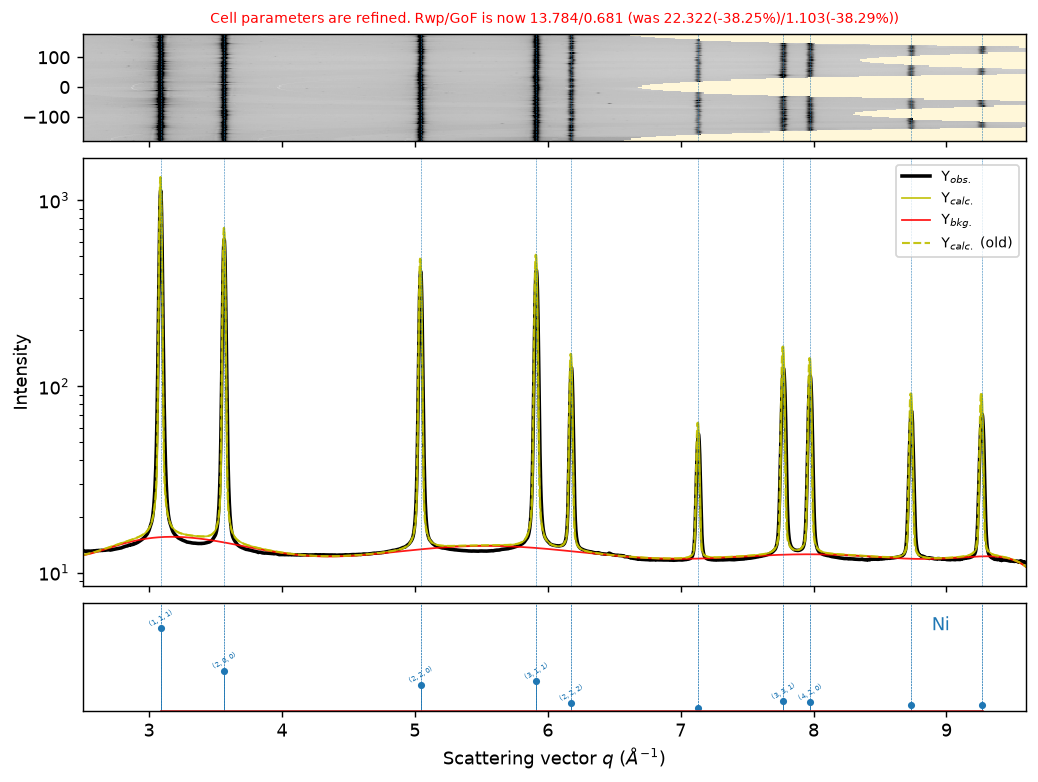

In [11]:
# Lattice parameter (aligns the peak positions)
sample.refine_cell_parameters(plot=True)

 ✅--Size broadening of all phases are refined. Rwp/GoF is now 10.134/0.500 (was 13.784(-26.48%)/0.681(-26.48%✨))


 ✅--Strain broadening of all phases are refined. Rwp/GoF is now 10.136/0.501 (was 10.134(0.02%)/0.500(0.02%❗))


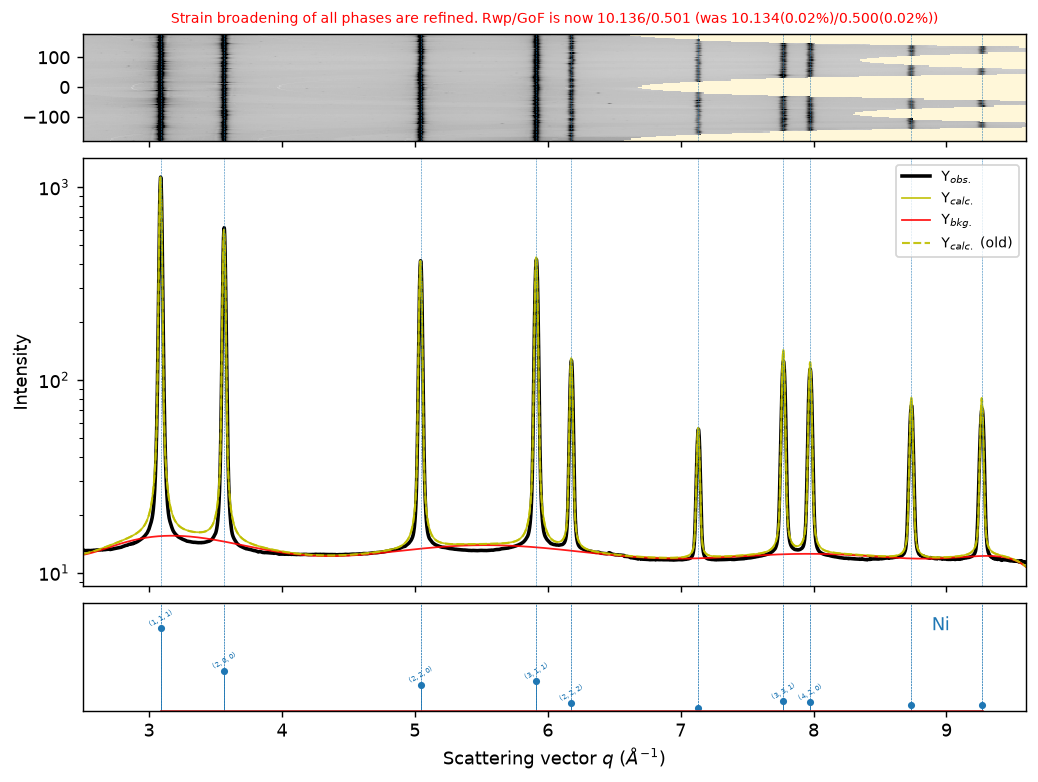

In [12]:
# Sample broadening: isotropic crystallite size, then isotropic microstrain
sample.refine_size_broadening(plot=False)
sample.refine_strain_broadening(plot=True)

## 7. Rietveld stage

### 7.1 Switch from Le Bail to Rietveld

With `set_LeBail(to=False)`, GSAS-II calculates the peak intensities from the Ni structure (structure factors,
Lorentz factor, multiplicity, Uiso). Rwp goes up, as expected, because the intensities are no longer free.

 ✅--After setting LeBail refinement to False, Rwp/GoF is now 17.902/0.884 (was 10.136(76.62%)/0.501(76.61%❗))


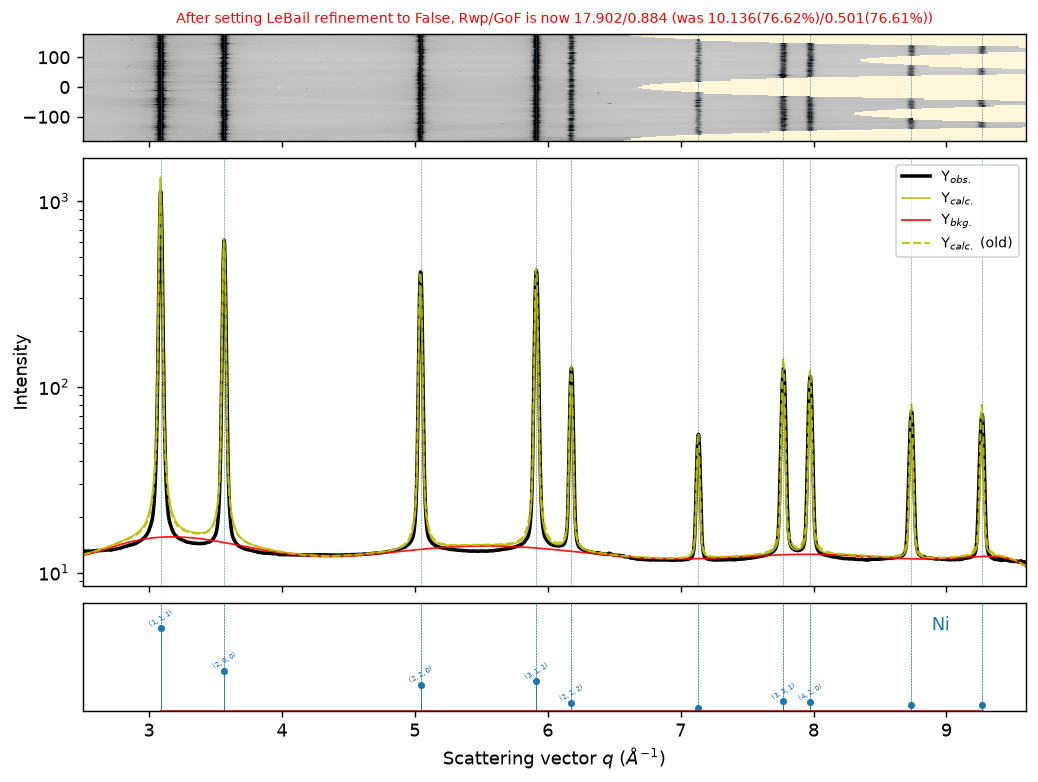

In [13]:
sample.set_LeBail(to=False, refine=True, plot=True)

### 7.2 Why preferred orientation is needed here

In the plot above, (111) is **over-calculated** and the high-q peaks are **under-calculated**. Refining Uiso
at this point would push it to a negative, unphysical value. `easyxrd` catches this and rejects the step
automatically, as the next cell shows.

The cake (`i2d`) also shows **spotty rings**: the sample contains a limited number of fairly large grains, and
some texture. The relative peak intensities therefore don't match an ideal random powder. We correct for this
with a **spherical-harmonics preferred-orientation model**. For the cubic m3m Laue class, an order-6 model adds
only two coefficients, C(4,1) and C(6,1).

In [14]:
# Refining Uiso before any texture correction (rejected by easyxrd if Uiso < 0)
sample.refine_site_property(site_ind=0, refinement_flags="U", plot=False)

 ❌--Refinement discarded because of negative Uiso (Ni/Ni0: Uiso=-0.00152674). Previous project restored; dataset and phases unchanged.


 ✅--Preferred orientation for all phases are refined. Rwp/GoF is now 13.953/0.689 (was 17.902(-22.06%)/0.884(-22.05%✨))


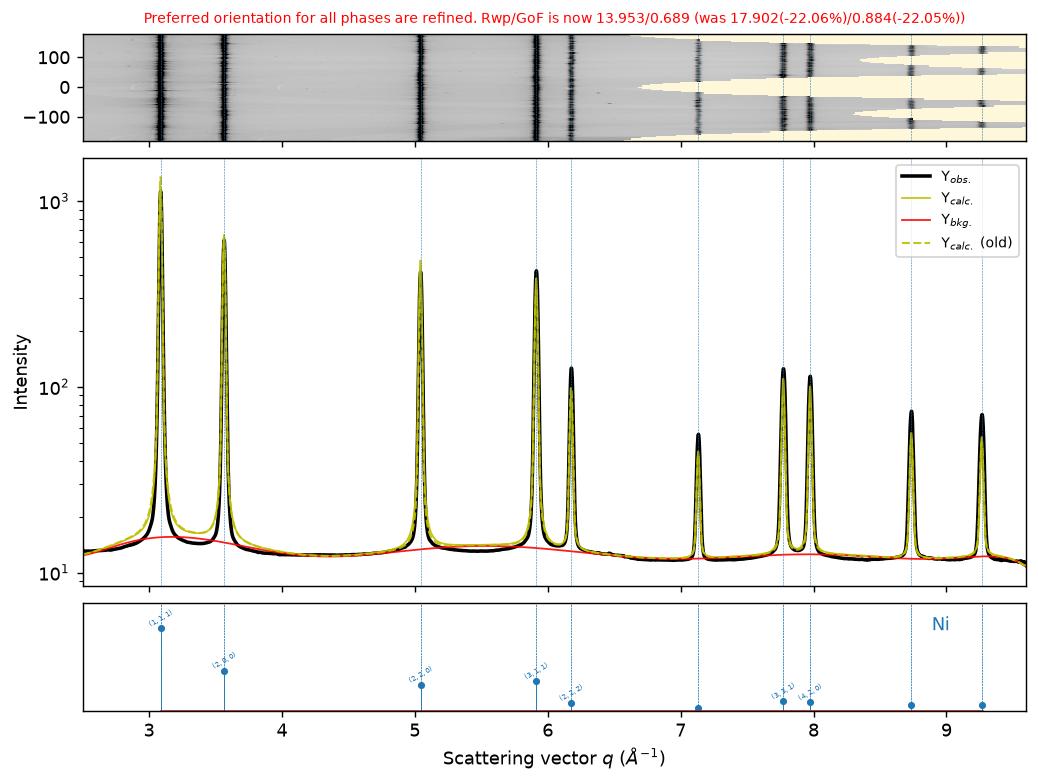

In [15]:
# Spherical-harmonics preferred orientation, order 6 (C(4,1) and C(6,1) for m3m)
sample.refine_preferred_orientation(harmonics_order=6, plot=True)

### 7.3 Atomic displacement parameter (Uiso) of Ni

With the texture correction in place, Uiso refines to a physically reasonable positive value.

 ✅--U property of Ni0 site of Ni phase is refined. Rwp/GoF is now 11.661/0.576 (was 13.953(-16.42%)/0.689(-16.43%✨))


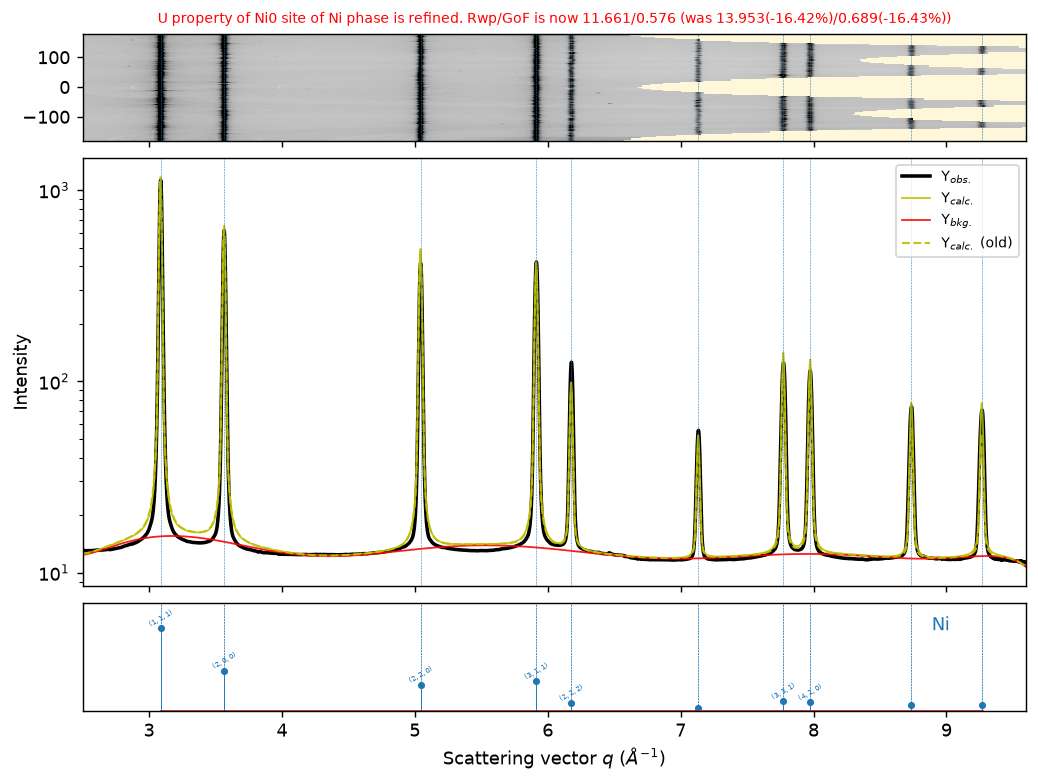

In [16]:
sample.refine_site_property(site_ind=0, refinement_flags="U", plot=True)

### 7.4 Final cycles

Re-refine the sample broadening, then the background with a more flexible 15-term polynomial, and finally
the lattice parameter.

 ✅--Size broadening of all phases are refined. Rwp/GoF is now 11.642/0.575 (was 11.661(-0.17%)/0.576(-0.17%❗))


 ✅--Strain broadening of all phases are refined. Rwp/GoF is now 11.630/0.574 (was 11.642(-0.10%)/0.575(-0.10%❗))


 ✅--Background with 15 coeffs is refined. Rwp/GoF is now 10.602/0.524 (was 11.630(-8.83%)/0.574(-8.74%))


 ✅--Cell parameters are refined. Rwp/GoF is now 8.532/0.421 (was 10.602(-19.53%)/0.524(-19.61%✨))


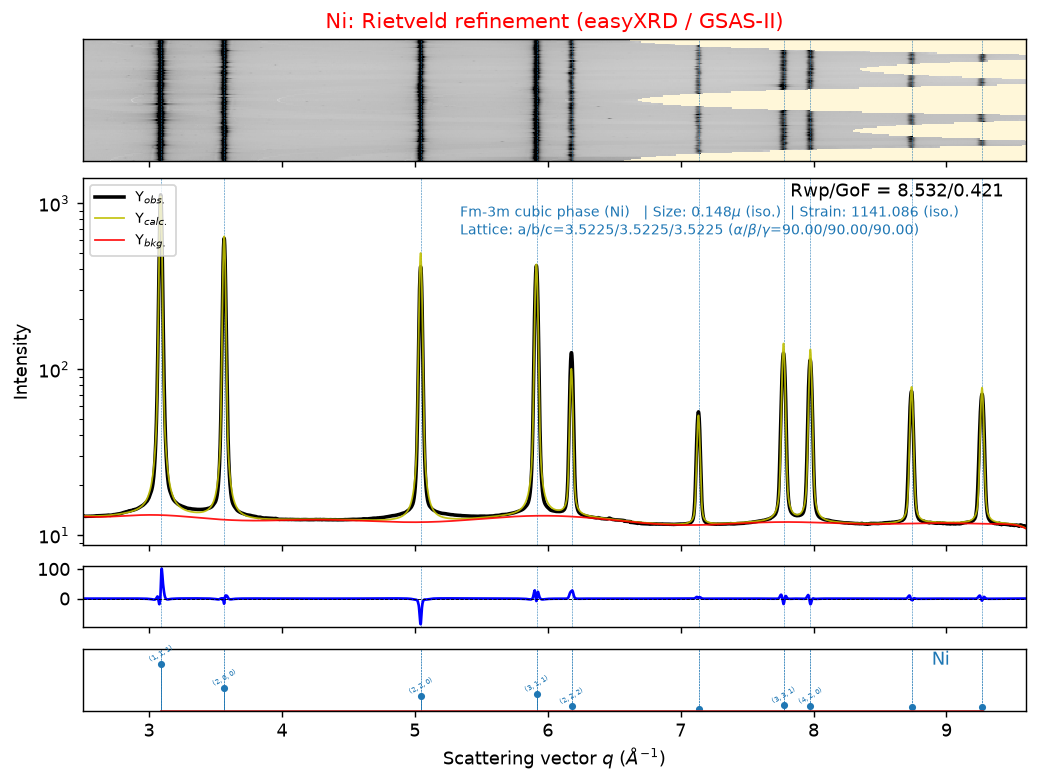

In [17]:
sample.refine_size_broadening(plot=False)
sample.refine_strain_broadening(plot=False)
sample.refine_background(num_coeffs=15, plot=False)
sample.refine_cell_parameters(plot=False)

sample.plot(title="Ni: Rietveld refinement (easyXRD / GSAS-II)")

## 8. Results

In [18]:
attrs = sample.ds.attrs
phase = sample.gpx.phases()[0]
hist_name = sample.gpx.histograms()[0].name
hap = phase.data["Histograms"][hist_name]
atom = phase.data["Atoms"][0]

try:
    cell, cell_esd = phase.get_cell_and_esd()
    a_str = f"{cell[0]:.5f} ± {cell_esd[0]:.5f} Å"
except Exception:
    a_str = f"{phase.data['General']['Cell'][1]:.5f} Å"

print("=== Refinement statistics ===")
print(f"Converged          : {attrs.get('converged')}")
print(f"Rwp                : {attrs['Rwp']:.3f} %")
print(f"GoF                : {attrs['GOF']:.3f}")
print(f"N obs / N vars     : {attrs.get('Nobs')} / {attrs.get('Nvars')}")
print()
print("=== Ni (Fm-3m) ===")
print(f"Lattice a          : {a_str}   (CIF start: 3.52558 Å)")
print(f"Uiso(Ni)           : {atom[10]:.5f} Å^2")
print(f"Crystallite size   : {hap['Size'][1][0]:.4f} µm (isotropic)")
print(f"Microstrain        : {hap['Mustrain'][1][0]:.1f} (x10^-6, isotropic)")
print(f"Pref. orientation  : {hap['Pref.Ori.'][0]}, order {hap['Pref.Ori.'][4]}, coeffs = "
      + ", ".join(f"{k}={float(v):.4f}" for k, v in hap['Pref.Ori.'][5].items()))
print()
print("=== Instrument parameters used (fixed, from _instrument_parameters.gpx) ===")
ip = sample.gpx.histograms()[0].data["Instrument Parameters"][0]
print("  " + ", ".join(f"{k}={float(ip[k][1]):.4f}" for k in ["Lam", "Zero", "U", "V", "W", "X", "Y", "Z", "SH/L"]))

=== Refinement statistics ===
Converged          : True
Rwp                : 8.532 %
GoF                : 0.421
N obs / N vars     : 7100 / 2

=== Ni (Fm-3m) ===
Lattice a          : 3.52254 Å   (CIF start: 3.52558 Å)
Uiso(Ni)           : 0.00303 Å^2
Crystallite size   : 0.1481 µm (isotropic)
Microstrain        : 1141.1 (x10^-6, isotropic)
Pref. orientation  : SH, order 6, coeffs = C(4,1)=0.0298, C(6,1)=0.4045

=== Instrument parameters used (fixed, from _instrument_parameters.gpx) ===
  Lam=0.1799, Zero=0.0000, U=-29.4296, V=13.7913, W=0.8709, X=0.0752, Y=-1.0844, Z=0.0408, SH/L=0.0055


**Notes on the results**

* **GoF < 1.** The 1D intensities are azimuthal *averages* from pyFAI, not raw counts. GSAS-II weights them
  as w = 1/I, which overestimates the uncertainties, so the absolute GoF is below 1. Use Rwp and the difference
  curve to judge the fit.
* **Lattice parameter.** The refined a matches the room-temperature literature value for Ni (~3.524 Å) to within
  about 0.05 %. Its absolute accuracy depends on the PONI distance/wavelength calibration.
* **Preferred orientation** here mainly corrects the grain statistics (spotty rings) and texture of this sample.
  Without it, Uiso refines to a negative value.

## 9. Export

Saved: Ni_refined.gpx, Ni_refined.nc, Ni_rietveld.pdf, Ni_rietveld_fit.dat


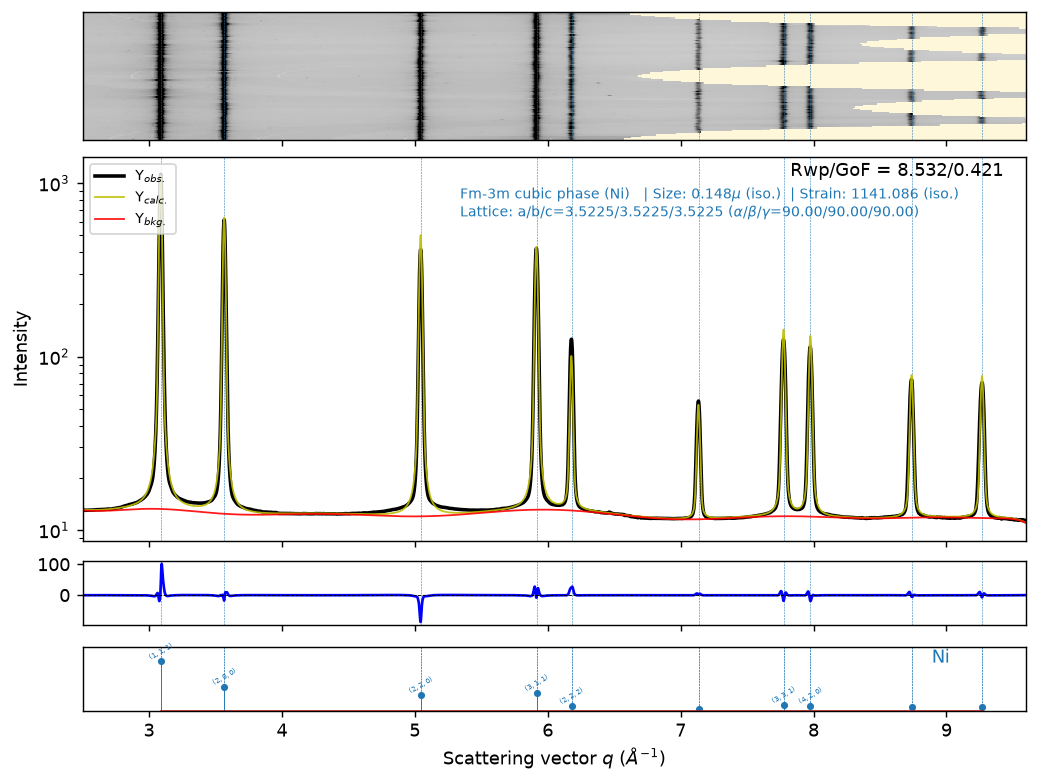

In [19]:
sample.export_gpx_to("Ni_refined.gpx")                          # GSAS-II project (open in the GSAS-II GUI)

# xarray dataset (i2d, i1d, fit, background). After refinement, ds.attrs holds some dict-valued
# GSAS-II entries (e.g. 'lastShifts') that NetCDF cannot store, so they are stringified in a copy.
ds_out = sample.ds.copy()
ds_out.attrs = {k: (v if isinstance(v, (str, int, float, np.number, np.ndarray, list, tuple)) and not isinstance(v, bool)
                    else str(v)) for k, v in sample.ds.attrs.items()}
ds_out.to_netcdf("Ni_refined.nc", engine="h5netcdf")
sample.plot(export_fig_as="Ni_rietveld.pdf")                    # publication figure

# Plain-text table of observed / calculated / background vs q
ds = sample.ds
cols = [ds.i1d.radial.values, ds.i1d.values]
names = ["q(1/A)", "Yobs"]
for k, n in [("i1d_refined", "Ycalc"), ("i1d_gsas_background", "Ybkg")]:
    if k in ds:
        cols.append(ds[k].values); names.append(n)
np.savetxt("Ni_rietveld_fit.dat", np.column_stack(cols), fmt="%.6e", header=" ".join(names))
print("Saved: Ni_refined.gpx, Ni_refined.nc, Ni_rietveld.pdf, Ni_rietveld_fit.dat")